In [2]:
# Define a small maze, actions and a Q-table.
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
maze = np.array([[0, 0, 1, 0, 0],
                 [1, 0, 1, 0, 1],
                 [0, 0, 0, 0, 0],
                 [0, 1, 1, 1, 0],
                 [0, 0, 0, 1, 0]])
start, goal = (0, 0), (4, 4)
actions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
Q = np.zeros((5, 5, 4))
alpha, gamma = 0.2, 0.95

In [4]:
# Apply an action and return the next position, reward and goal status.
def step(position, action):
    row = position[0] + actions[action][0]
    column = position[1] + actions[action][1]
    if not (0 <= row < 5 and 0 <= column < 5) or maze[row, column] == 1:
        return position, -0.5, False
    next_position = (row, column)
    done = next_position == goal
    return next_position, 10 if done else -0.1, done

In [10]:
#explore the maze and Q learning 
for episode in range(2000):
    position=start
    epi=max(0.05 , 0.9*(0.997**episode))
    for move in range(100):
        if rng.random()<epi:
            action=int(rng.integers(4))
        else:
            action=int(np.argmax(Q[position]))

        next_position,reward , done=step(position,action)
        target=reward if done else reward+gamma*np.max(Q[next_position])
        Q[position][action]+=alpha*(target-Q[position][action])
        position=next_position
        if done:
            break
        

Reached goal: True
Learned path: [(0, 0), (0, 1), (1, 1), (2, 1), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]


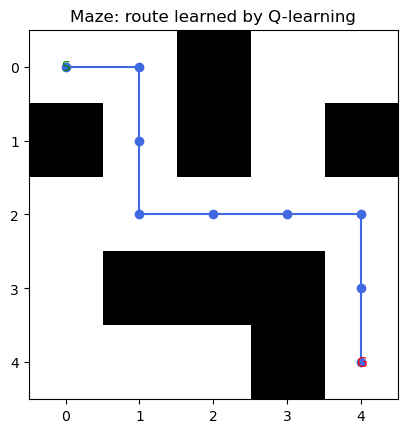

In [12]:

# Test the learned greedy policy and show its route through the maze.
position = start
path = [position]
for move in range(50):
    action = int(np.argmax(Q[position]))
    position, reward, done = step(position, action)
    path.append(position)
    if done:
        break
print('Reached goal:', position == goal)
print('Learned path:', path)
plt.imshow(maze, cmap='Greys', vmin=0, vmax=1)
plt.plot([p[1] for p in path], [p[0] for p in path], 'o-', color='royalblue')
plt.text(0, 0, 'S', color='green', ha='center', va='center')
plt.text(4, 4, 'G', color='red', ha='center', va='center')
plt.xticks(range(5))
plt.yticks(range(5))
plt.title('Maze: route learned by Q-learning')
plt.show()